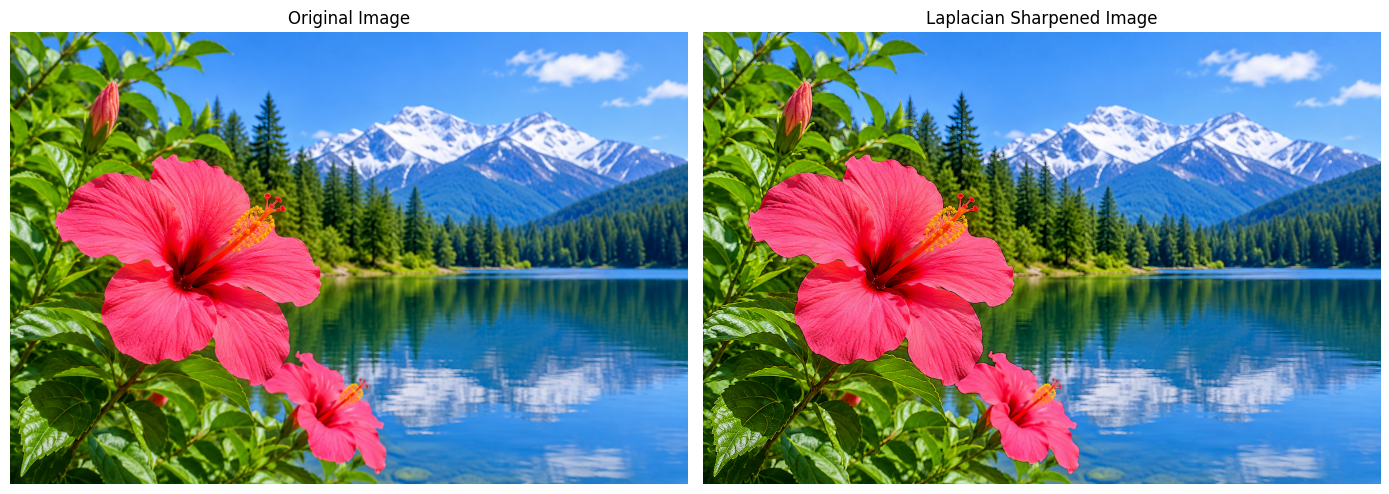

Laplacian Sharpening Completed Successfully!


In [1]:
# Laplacian Filter
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("image.jpg")

if image is None:
    raise FileNotFoundError("Image not found!")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

H, S, I = cv2.split(hsv_image)

kernel = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

laplacian = cv2.filter2D(
    I, cv2.CV_32F, kernel
)

sharpened_I = I.astype(np.float32) + laplacian

sharpened_I = np.clip(sharpened_I, 0, 255)
sharpened_I = sharpened_I.astype(np.uint8)

sharpened_hsv = cv2.merge((H, S, sharpened_I))

sharpened_image = cv2.cvtColor(
    sharpened_hsv, cv2.COLOR_HSV2RGB
)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharpened_image)
plt.title("Laplacian Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "laplacian_sharpened_image.jpg",
    cv2.cvtColor(sharpened_image, cv2.COLOR_RGB2BGR)
)

print("Laplacian Sharpening Completed Successfully!")
